**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: ELDA ESTEFANÍA LARA CRUZ
*   MATRÍCULA: A01747420

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [20]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [21]:
cardio_df = pd.read_csv('/content/heart_disease.csv', index_col='id')
cardio_df.info()
print()
print(cardio_df.nunique())

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB

age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg       3
thalch      119
exang         2
oldpeak     

**Respuesta 1.**

* El dataframe `cardio_df` tiene 918 registros y 15 columnas (`id` es el índice).
* Según `info()`, hay **7 columnas numéricas** (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `ca`, `num`: 2 `int64` y 5 `float64`) y **8 columnas de texto / no numéricas**: 6 de tipo `str` (`sex`, `origin`, `cp`, `restecg`, `slope`, `thal`) y 2 de tipo `object` (`fbs`, `exang`), que en realidad son booleanas (`True`/`False`) pero con valores faltantes.
* Valores únicos: `sex` (2), `fbs` (2), `exang` (2), `restecg` (3), `thal` (3), `slope` (3), `origin` (4), `cp` (4), `ca` (4), `num` (5), `age` (50), `oldpeak` (53), `trestbps` (60), `thalch` (119) y `chol` (216).

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [22]:
# Variables numéricas con pocos valores únicos
num_cols = cardio_df.select_dtypes(include='number').columns
print(cardio_df[num_cols].nunique().sort_values())

# ca y num son ordinales: se conserva el orden natural de sus categorías
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)
print()
print(cardio_df[['ca', 'num']].dtypes)

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64

ca     category
num    category
dtype: object


**Respuesta 2.**

Entre las columnas numéricas, `ca` (4 valores únicos) y `num` (5 valores únicos) son categóricas codificadas como número. Las demás (`age`, `oldpeak`, `trestbps`, `thalch`, `chol`) tienen muchos valores distintos y son realmente continuas.

* `ca` es el número de vasos principales coloreados (0 a 3): es **ordinal**, pues 3 vasos implican más compromiso que 0.
* `num` es el grado de enfermedad (0 = sano, 1 a 4 = enfermedad de menor a mayor grado): también es **ordinal**.

Ambas se convirtieron a categóricas ordenadas, con el orden natural de sus valores. `fbs` y `exang` ya son booleanas y no son numéricas, por lo que no requieren esta conversión.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [23]:
# Variables numéricas
num_cols = cardio_df.select_dtypes(include='number').columns
num_stats = cardio_df[num_cols].describe().T
num_stats['skew'] = cardio_df[num_cols].skew()
num_stats['kurtosis'] = cardio_df[num_cols].kurtosis()
print(num_stats.round(2))

# Variables categóricas
cat_cols = cardio_df.select_dtypes(exclude='number').columns
print()
print(cardio_df[cat_cols].describe().T)
for col in cat_cols:
    print()
    print(cardio_df[col].value_counts(dropna=False))

          count    mean    std   min    25%    50%    75%    max  skew  \
age       918.0   53.53   9.41  28.0   47.0   54.0   60.0   77.0 -0.19   
trestbps  859.0  132.29  18.54  80.0  120.0  130.0  140.0  200.0  0.63   
chol      888.0  242.19  53.42  85.0  216.0  223.0  268.0  603.0  1.64   
thalch    863.0  137.53  25.95  60.0  120.0  140.0  157.0  202.0 -0.21   
oldpeak   856.0    0.88   1.09  -2.6    0.0    0.5    1.5    6.2  1.04   

          kurtosis  
age          -0.38  
trestbps      0.63  
chol          6.57  
thalch       -0.48  
oldpeak       1.12  

         count unique           top   freq
sex        918      2          Male    724
origin     918      4     Cleveland    304
cp         918      4  asymptomatic    495
fbs        829      2         False    691
restecg    918      3        normal    551
exang      863      2         False    526
slope      610      3          flat    345
ca       309.0    4.0           0.0  181.0
thal       434      3        normal    19

**Respuesta 3.**

*Numéricas* (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`):

* `age` (sesgo −0.19, curtosis −0.38) y `thalch` (sesgo −0.21, curtosis −0.48) son prácticamente simétricas y con colas ligeras.
* `trestbps` tiene un sesgo positivo moderado (0.63).
* `oldpeak` tiene sesgo positivo (1.04) y curtosis de 1.12: la mayoría de los valores está cerca de 0 y hay pocos valores altos.
* `chol` es la más asimétrica (sesgo 1.64) y con colas muy pesadas (curtosis 6.57): la media (242) es mayor que la mediana (223) por valores extremos como 603 mg/dl.

*Categóricas* (`sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`, `num`):

* Predominan los hombres (724 de 918) y el dolor torácico asintomático (495).
* `restecg` es mayormente normal (551) y `num` tiene más pacientes sanos (411) que de cualquier grado de enfermedad.
* Las tablas de frecuencia muestran los faltantes (`NaN`): `slope` (308), `ca` (609) y `thal` (484) tienen muchos, lo que se aborda en el ejercicio 4.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

ca          66.34
thal        52.72
slope       33.55
fbs          9.69
oldpeak      6.75
trestbps     6.43
thalch       5.99
exang        5.99
chol         3.27
sex          0.00
origin       0.00
cp           0.00
age          0.00
restecg      0.00
num          0.00
dtype: float64

Columnas eliminadas: ['slope', 'ca', 'thal']


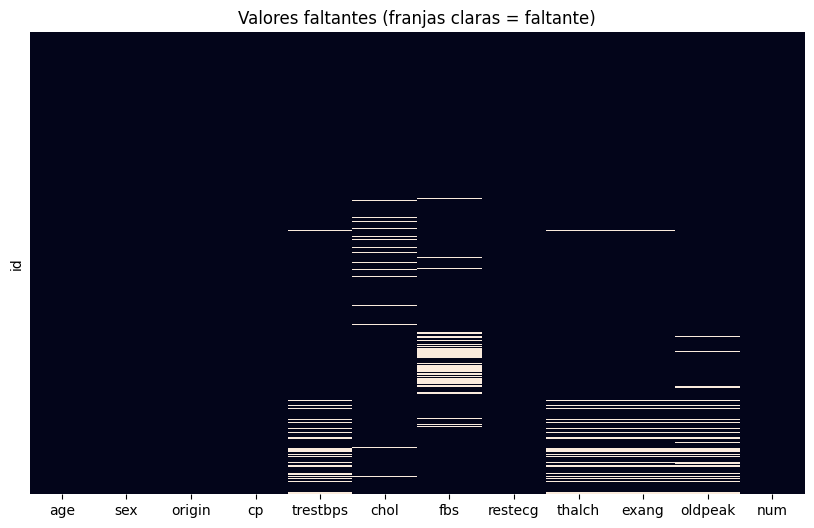

0    852
1     10
2      1
3      1
4     54
Name: count, dtype: int64


In [24]:
missing_pct = cardio_df.isna().mean() * 100
print(missing_pct.round(2).sort_values(ascending=False))

cols_to_drop = missing_pct[missing_pct > 30].index
print('\nColumnas eliminadas:', list(cols_to_drop))
cardio_df = cardio_df.drop(columns=cols_to_drop)

plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False)
plt.title('Valores faltantes (franjas claras = faltante)')
plt.show()

# Número de variables faltantes por fila entre las candidatas al patrón simultáneo
co_cols = ['trestbps', 'thalch', 'exang', 'oldpeak']
print(cardio_df[co_cols].isna().sum(axis=1).value_counts().sort_index())

**Respuesta 4.**

* Las columnas con más del 30% de faltantes son `ca` (66.34%), `thal` (52.72%) y `slope` (33.55%); se **eliminaron**.
* Las demás tienen menos del 10% de faltantes: `fbs` (9.69%), `oldpeak` (6.75%), `trestbps` (6.43%), `thalch` (5.99%), `exang` (5.99%) y `chol` (3.27%).
* **Variables con faltantes simultáneos:** `trestbps`, `thalch`, `exang` y `oldpeak`. En el mapa de calor aparecen como bandas horizontales alineadas, y en 54 filas faltan las cuatro a la vez; solo 12 filas más tienen faltante en alguna de ellas. `chol` y `fbs` tienen faltantes en filas distintas.
* **¿Tiene sentido clínico?** Sí. `thalch` (frecuencia cardíaca máxima), `exang` (angina inducida por ejercicio) y `oldpeak` (depresión del segmento ST con el ejercicio) provienen de la misma prueba de esfuerzo. Si el paciente no se sometió a la prueba (por ejemplo, por una contraindicación o porque no podía hacer ejercicio) o no se registró, las tres faltan juntas. La presión arterial en reposo (`trestbps`) suele medirse como parte del protocolo de esa misma evaluación, así que es razonable que falte en el mismo registro incompleto. En cambio, `chol` y `fbs` vienen de análisis de laboratorio independientes y por eso su patrón es distinto.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [25]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = []
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr.append(df[BM][str_att_name].dropna())
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,orientation='horizontal')
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim(att_range)
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [26]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

--- age ---


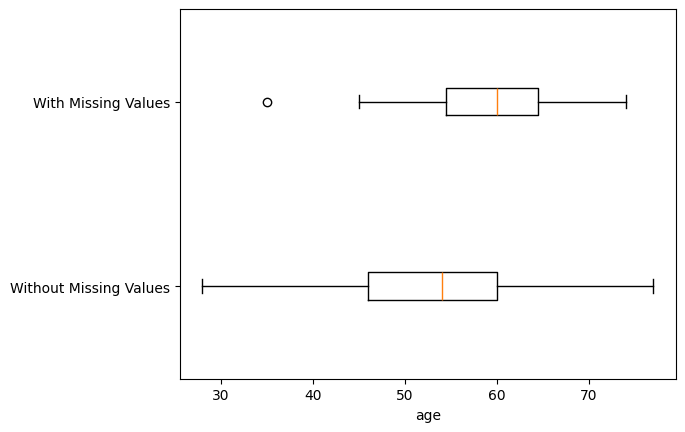

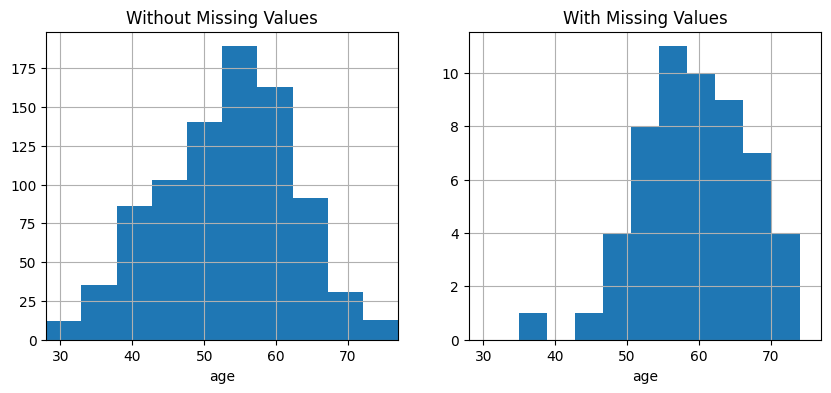

p-value of t-test: 1.5041244185890902e-06
--- chol ---


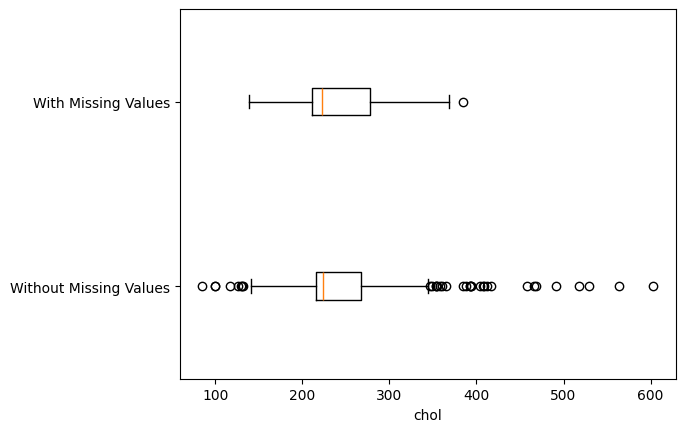

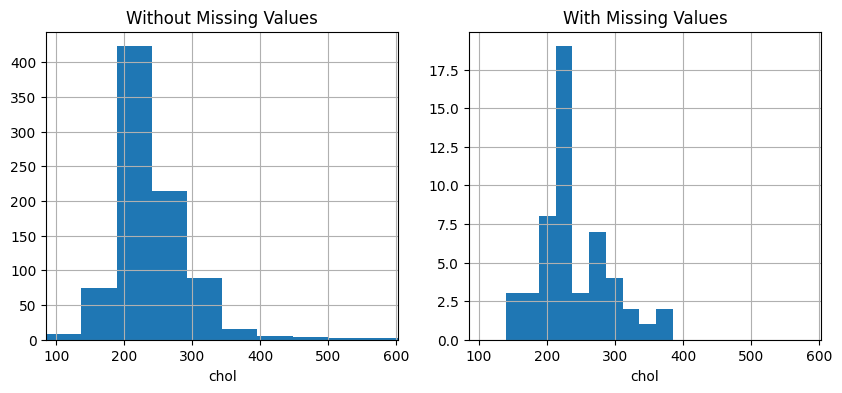

p-value of t-test: 0.7165289974295672
--- restecg ---


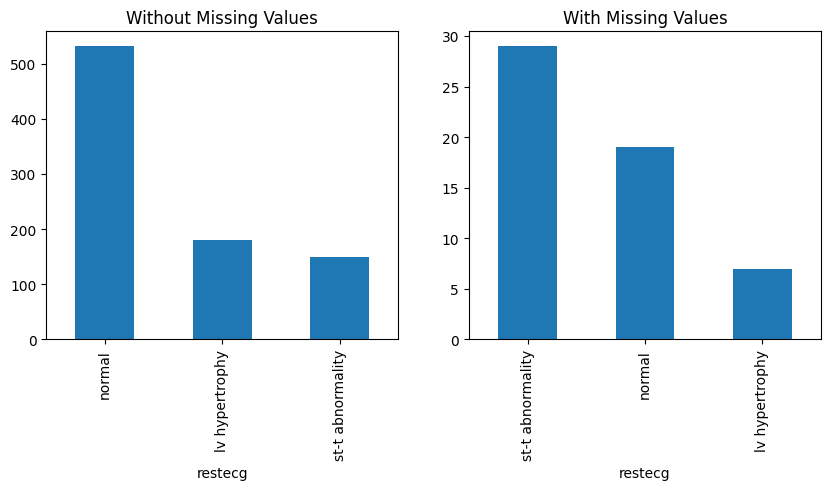

p-value of Chi_squared test: 1.1472889573985467e-09
--- cp ---


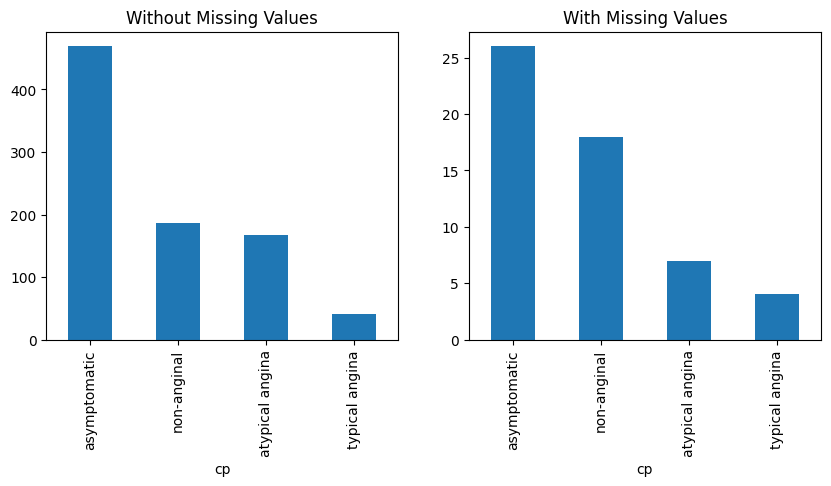

p-value of Chi_squared test: 0.15420097177251701


In [27]:
BM_MV = cardio_df['thalch'].isna()

for col in ['age', 'chol']:
    print(f'--- {col} ---')
    Diagnose_MV_Numerical(cardio_df, col, BM_MV)

for col in ['restecg', 'cp']:
    print(f'--- {col} ---')
    Diagnose_MV_Categorical(cardio_df, col, BM_MV)

**Respuesta 5.**

Se comparó el grupo con faltantes en `thalch` contra el grupo sin faltantes (nivel de significancia 0.05):

| Variable | Prueba | p-value | ¿Diferencia significativa? |
|---|---|---|---|
| `age` | t de Student | 1.5e-06 | Sí |
| `chol` | t de Student | 0.717 | No |
| `restecg` | Chi cuadrada | 1.1e-09 | Sí |
| `cp` | Chi cuadrada | 0.154 | No |

* **`age`:** los pacientes con `thalch` faltante son mayores (el boxplot y el histograma están desplazados a la derecha; la edad media es de aprox. 59 años contra 53 en el grupo sin faltantes).
* **`chol`:** las distribuciones de ambos grupos son similares, sin relación con la ausencia.
* **`restecg`:** la distribución es muy distinta. Entre los pacientes con `thalch` faltante predomina la anomalía ST-T (aprox. 53%), mientras que entre los que sí tienen el dato predomina el electrocardiograma normal (aprox. 62%).
* **`cp`:** no hay diferencias significativas en el tipo de dolor torácico.

**Mecanismo de ausencia:** no es **MCAR**, porque la probabilidad de que falte `thalch` depende de otras variables observadas (`age` y `restecg`); si los faltantes fueran completamente aleatorios no habría diferencias entre los grupos. El mecanismo es compatible con **MAR**: la ausencia se explica por variables que sí observamos. Como los faltantes ocurren en las mismas filas, la conclusión se extiende a `trestbps`, `exang` y `oldpeak`. Con los datos disponibles no se puede descartar por completo que dependa también del propio valor no observado (MNAR); por ejemplo, un paciente demasiado grave para hacer ejercicio. Por eso MAR es la mejor justificación, no una certeza.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

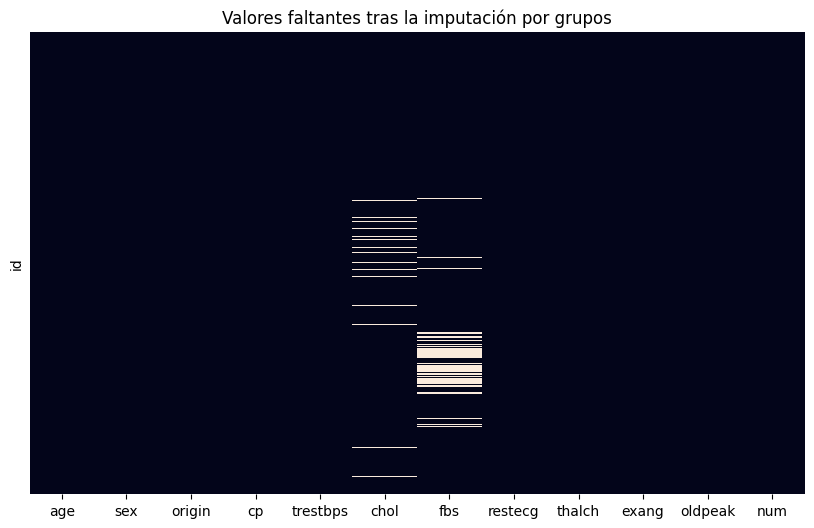

In [28]:
# Variables numéricas: mediana por grupo de restecg
for col in ['trestbps', 'thalch', 'oldpeak']:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# Variable no numérica (exang): moda por grupo de restecg
cardio_df['exang'] = cardio_df['exang'].astype('boolean')
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))

plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False)
plt.title('Valores faltantes tras la imputación por grupos')
plt.show()

**Respuesta 6.**

Se imputaron por grupos de `restecg` las variables con el patrón de faltantes simultáneos (`trestbps`, `thalch`, `exang` y `oldpeak`), porque el ejercicio 5 mostró que la ausencia está relacionada con `restecg` (mecanismo MAR). Para las numéricas se usó la **mediana** de cada grupo (robusta a valores extremos) y para `exang`, que no es numérica, la **moda** de cada grupo. En el mapa de calor ya no hay faltantes en estas cuatro variables; solo quedan `chol` y `fbs`.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [29]:
print(cardio_df.isna().sum()[lambda s: s > 0])

# Numérica: mediana
imp_median = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_median.fit_transform(cardio_df[['chol']])

# Booleana: moda
imp_mode = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_mode.fit_transform(cardio_df[['fbs']])

print('\nFaltantes restantes:', cardio_df.isna().sum().sum())

chol    30
fbs     89
dtype: int64

Faltantes restantes: 0


**Respuesta 7.**

Las variables que aún tenían faltantes eran `chol` (30) y `fbs` (89), imputadas con `SimpleImputer` sobre toda la columna:

* **`chol`: `median`.** La variable tiene un sesgo alto (1.64), curtosis de 6.57 y valores extremos (hasta 603 mg/dl). La media se desplaza por esos extremos; la mediana representa mejor un valor típico.
* **`fbs`: `most_frequent`.** Es una variable booleana (categórica), para la que la media y la mediana no tienen sentido. Se imputa con la categoría más común, `False` (aprox. 83% de los valores observados).

Tras la imputación no quedan valores faltantes en el dataframe.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

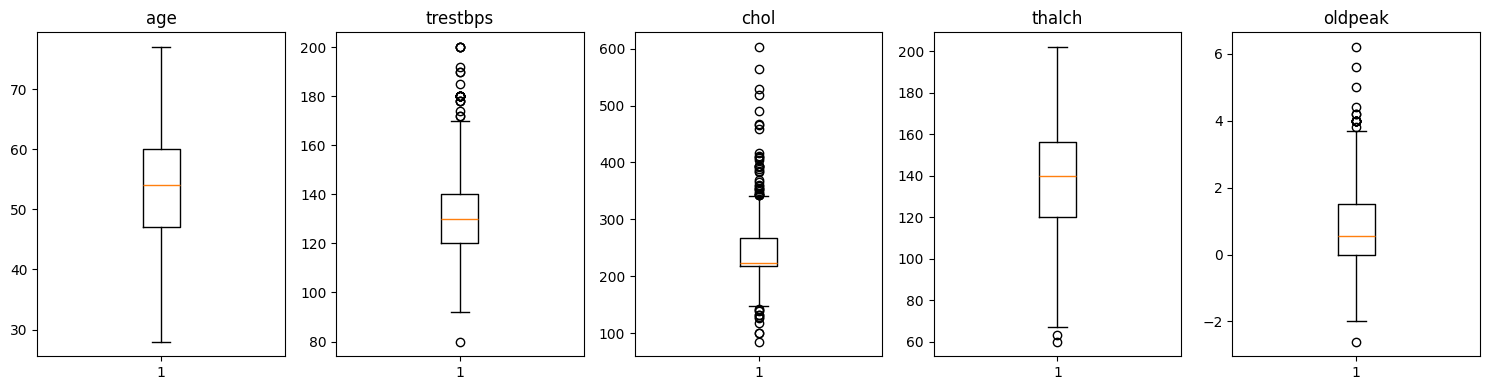

age: 0 atípicos -> []
trestbps: 27 atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
chol: 44 atípicos -> [ 85. 100. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 342. 342.
 344. 347. 349. 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392.
 393. 394. 394. 404. 407. 409. 412. 417. 458. 466. 468. 491. 518. 529.
 564. 603.]
thalch: 2 atípicos -> [60. 63.]
oldpeak: 16 atípicos -> [-2.6  3.8  4.   4.   4.   4.   4.   4.   4.   4.   4.2  4.2  4.4  5.
  5.6  6.2]


In [30]:
num_cols = cardio_df.select_dtypes(include='number').columns

fig, axes = plt.subplots(1, len(num_cols), figsize=(15, 4))
outliers_plot = {}
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])
    ax.set_title(col)
    outliers_plot[col] = np.sort(bp['fliers'][0].get_ydata())
plt.tight_layout()
plt.show()

for col, vals in outliers_plot.items():
    print(f'{col}: {len(vals)} atípicos -> {vals}')

**Respuesta 8.**

Valores atípicos obtenidos de los `fliers` de cada boxplot (puntos fuera de 1.5 × IQR):

* `age`: ninguno.
* `trestbps`: 27 (un valor bajo, 80, y 26 altos entre 172 y 200).
* `chol`: 44 (11 bajos, entre 85 y 142, y 33 altos entre 342 y 603).
* `thalch`: 2 (60 y 63).
* `oldpeak`: 16 (uno negativo, −2.6, y 15 altos entre 3.8 y 6.2).

Los atípicos de `chol` y `oldpeak` son consistentes con el sesgo positivo que se observó en el ejercicio 3.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [31]:
q1 = cardio_df['trestbps'].quantile(0.25)
q3 = cardio_df['trestbps'].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Q1={q1}, Q3={q3}, IQR={iqr}, límite inferior={lower}, límite superior={upper}')

outlier_mask = (cardio_df['trestbps'] < lower) | (cardio_df['trestbps'] > upper)
outliers_iqr = np.sort(cardio_df.loc[outlier_mask, 'trestbps'].values)
print(f'{len(outliers_iqr)} atípicos -> {outliers_iqr}')

print('¿Coinciden con el boxplot?', np.array_equal(outliers_iqr, outliers_plot['trestbps']))

Q1=120.0, Q3=140.0, IQR=20.0, límite inferior=90.0, límite superior=170.0
27 atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
¿Coinciden con el boxplot? True


**Respuesta 9.**

Para `trestbps`: Q1 = 120, Q3 = 140 e IQR = 20, por lo que los límites son 90 (inferior) y 170 (superior). Los valores fuera de ese rango son 27 (uno por debajo, 80, y 26 por encima), y **coinciden exactamente** con los obtenidos del boxplot en el ejercicio 8, porque el boxplot de matplotlib usa la misma regla de 1.5 × IQR sobre los mismos cuartiles.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros restantes: 891


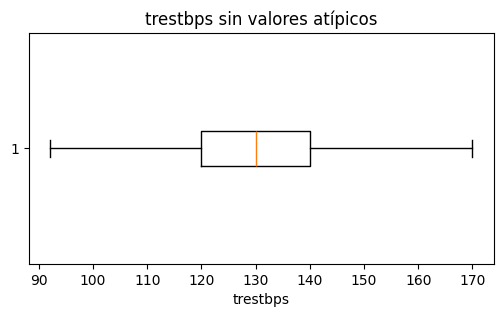

In [32]:
cardio_df = cardio_df[~outlier_mask]
print('Registros restantes:', len(cardio_df))

plt.figure(figsize=(6, 3))
plt.boxplot(cardio_df['trestbps'], orientation='horizontal')
plt.xlabel('trestbps')
plt.title('trestbps sin valores atípicos')
plt.show()

**Respuesta 10.**

Se eliminaron los 27 registros con `trestbps` atípico, por lo que el dataframe pasó de 918 a 891 registros. El boxplot final muestra una distribución sin atípicos, con valores entre 92 y 170 mm Hg. Al eliminar filas completas también se pierde la información de esos pacientes en las demás variables; aquí se hizo porque el ejercicio lo pide, aunque presiones altas pueden ser clínicamente reales y no necesariamente errores.

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

*   Anthropic. (2026). *Claude Sonnet 5.5* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis y conclusiones. https://claude.ai/

---